# Screened Coulomb Potential

Numerical solution of the radial Schrödinger equation for a screened Coulomb potential using the finite-difference Hamiltonian method. The plot is generated and stored in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

e = 3.795                 # sqrt(e^2), in the chosen units
hbar_c = 1973.0           # eV Å
mc2 = 0.511e6             # electron rest energy, eV

hbar2_over_2m = (hbar_c**2) / (2 * mc2)

In [2]:
def hamiltonian_matrix(delta_r, potential_values):
    potential_values = np.asarray(potential_values, dtype=float)
    if delta_r <= 0:
        raise ValueError("delta_r must be greater than 0")
    if potential_values.ndim != 1:
        raise ValueError("potential_values must be a one-dimensional array.")
    if potential_values.size == 0:
        raise ValueError("potential_values cannot be empty.")

    interior_points = len(potential_values)
    main_diag = (2 * hbar2_over_2m) / (delta_r**2) + potential_values
    off_diag = np.full(interior_points - 1, (-1 * hbar2_over_2m) / (delta_r**2))
    hamiltonian = (np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1))
    return hamiltonian

In [3]:
def effective_potential(r, l, potential):
    potential_values = potential + hbar2_over_2m * (l * (l + 1) / (r**2))
    return potential_values

def screened_coulomb_potential(interior_grid, a):
    return (-e**2 / interior_grid) * np.exp(-interior_grid / a)

In [4]:
def solve_potential(ri, rf, interior_points, l, state_index, a):
    delta_r = (rf - ri) / (interior_points + 1)
    interior_grid = ri + delta_r * np.arange(1, interior_points + 1)

    potential = screened_coulomb_potential(interior_grid, a)
    potential_values = effective_potential(interior_grid, l, potential)
    H = hamiltonian_matrix(delta_r, potential_values)
    eigenvalues, eigenvectors = np.linalg.eigh(H)

    phi_interior = eigenvectors[:, state_index]
    if phi_interior[np.argmax(np.abs(phi_interior))] < 0:
        phi_interior = -phi_interior
    energy_value = eigenvalues[state_index]
    phi = np.concatenate(([0.0], phi_interior, [0.0]))
    normalization = np.sum(np.abs(phi)**2) * delta_r
    phi_normalized = phi / np.sqrt(normalization)
    full_grid = np.concatenate(([ri], interior_grid, [rf]))
    return full_grid, phi_normalized, energy_value

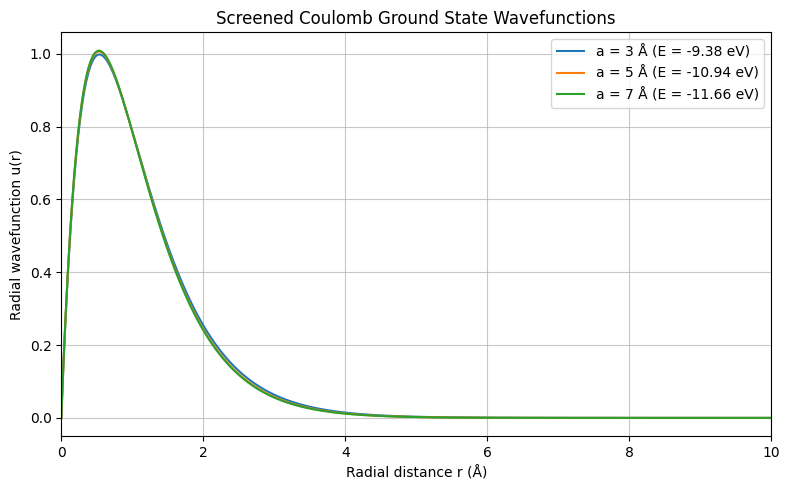

In [5]:
a = 3
ri = 1e-4
rf = 20.0
interior_points = 2000
l = 0
state_index = 0
a_list = [3.0, 5.0, 7.0]

plt.figure(figsize=(8, 5))
for a in a_list:
    grid, u_norm, energy = solve_potential(ri, rf, interior_points, l, state_index, a)
    plt.plot(grid, u_norm, label=f"a = {a:.0f} Å (E = {energy:.2f} eV)")

plt.grid(True, alpha=0.7)
plt.xlim(0, 10)
plt.xlabel("Radial distance r (Å)")
plt.ylabel("Radial wavefunction u(r)")
plt.title("Screened Coulomb Ground State Wavefunctions")
plt.legend()
plt.tight_layout()
plt.show()